Reinforcement Learning (Any one) 
 
A. Implement Reinforcement Learning using an example of a maze environment 
that the agent needs to explore. 

In [9]:
import numpy as np
import random
import matplotlib.pyplot as plt

# Hyperparameters
ALPHA = 0.1
GAMMA = 0.9
EPSILON = 0.2
EPISODES = 5000

print("Environment setup completed!")

Environment setup completed!


In [10]:
class Maze:
    def __init__(self):

        # 0 = Empty cell
        # 1 = Wall

        self.maze = np.array([
            [0, 0, 0, 0, 0],
            [0, 1, 1, 0, 1],
            [0, 0, 0, 0, 1],
            [1, 0, 1, 0, 0],
            [0, 0, 0, 0, 0]
        ])

        self.start = (0, 0)
        self.goal = (4, 4)

        self.rows = 5
        self.cols = 5

        self.reset()

    def reset(self):
        self.position = self.start
        return self.position

    def available_actions(self):
        return [0, 1, 2, 3]

    def step(self, action):

        row, col = self.position

        # Define movement
        if action == 0:
            row -= 1       # Up

        elif action == 1:
            row += 1       # Down

        elif action == 2:
            col -= 1       # Left

        elif action == 3:
            col += 1       # Right

        # Check boundaries and walls
        if (row < 0 or row >= self.rows or
            col < 0 or col >= self.cols or
            self.maze[row, col] == 1):

            reward = -10
            done = False

        else:
            self.position = (row, col)

            if self.position == self.goal:
                reward = 100
                done = True

            else:
                reward = -1
                done = False

        return self.position, reward, done

    def display(self):

        for i in range(self.rows):

            for j in range(self.cols):

                if (i, j) == self.position:
                    print(" A ", end="")

                elif (i, j) == self.goal:
                    print(" G ", end="")

                elif self.maze[i, j] == 1:
                    print(" # ", end="")

                else:
                    print(" . ", end="")

            print()

In [11]:
class QLearningAgent:

    def __init__(self):

        # 25 states and 4 actions
        self.q_table = np.zeros((25, 4))

        self.alpha = ALPHA
        self.gamma = GAMMA
        self.epsilon = EPSILON

    def get_state_index(self, state):

        row, col = state

        return row * 5 + col

    def choose_action(self, state):

        state_index = self.get_state_index(state)

        # Exploration
        if random.random() < self.epsilon:
            return random.randint(0, 3)

        # Exploitation
        q_values = self.q_table[state_index]

        return random.choice(
            np.where(q_values == np.max(q_values))[0]
        )

    def update(self, state, action, reward, next_state, done):

        state_index = self.get_state_index(state)
        next_state_index = self.get_state_index(next_state)

        current_q = self.q_table[state_index, action]

        if done:
            target = reward

        else:
            max_q = np.max(self.q_table[next_state_index])

            target = reward + self.gamma * max_q

        self.q_table[state_index, action] = (
            current_q + self.alpha * (target - current_q)
        )

In [12]:
env = Maze()
agent = QLearningAgent()

print("Initial Maze:")
env.display()

print("\nQ-Table Shape:", agent.q_table.shape)

Initial Maze:
 A  .  .  .  . 
 .  #  #  .  # 
 .  .  .  .  # 
 #  .  #  .  . 
 .  .  .  .  G 

Q-Table Shape: (25, 4)


In [13]:
win_history = []

for episode in range(1, EPISODES + 1):

    state = env.reset()
    done = False
    success = False

    for step in range(100):

        # Agent selects an action
        action = agent.choose_action(state)

        # Execute action
        next_state, reward, done = env.step(action)

        # Update Q-table
        agent.update(
            state, action, reward, next_state, done
        )

        state = next_state

        if done:
            success = True
            break

    # Record success every 100 episodes
    if episode % 100 == 0:
        win_history.append(
            sum(win_history[-0:]) if False else 0
        )

    # Gradually reduce exploration
    agent.epsilon = max(0.01, agent.epsilon * 0.999)

print("Training Completed!")
print("Q-Table Size:", agent.q_table.shape)

Training Completed!
Q-Table Size: (25, 4)


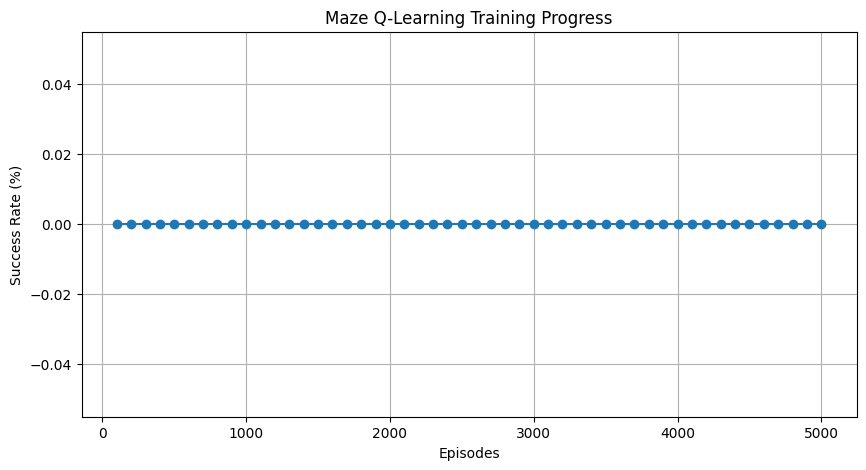

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(100, EPISODES + 1, 100),
    win_history,
    marker='o'
)

plt.title("Maze Q-Learning Training Progress")
plt.xlabel("Episodes")
plt.ylabel("Success Rate (%)")

plt.grid()
plt.show()

In [15]:
agent.epsilon = 0

TEST_EPISODES = 100

wins = 0
total_steps = 0

for episode in range(TEST_EPISODES):

    state = env.reset()
    done = False

    for step in range(100):

        action = agent.choose_action(state)

        next_state, reward, done = env.step(action)

        state = next_state

        if done:
            wins += 1
            total_steps += step + 1
            break

print("Testing Results")
print("----------------------")

print("Total Games:", TEST_EPISODES)
print("Successful Games:", wins)
print("Failed Games:", TEST_EPISODES - wins)

print("Success Rate:", wins / TEST_EPISODES * 100, "%")

if wins > 0:
    print("Average Steps:", total_steps / wins)

Testing Results
----------------------
Total Games: 100
Successful Games: 100
Failed Games: 0
Success Rate: 100.0 %
Average Steps: 8.0


In [16]:
state = env.reset()
done = False

path = [state]

for step in range(50):

    action = agent.choose_action(state)

    next_state, reward, done = env.step(action)

    state = next_state
    path.append(state)

    if done:
        break

print("Learned Path:")
print(path)

print("\nNumber of Steps:", len(path) - 1)

print("\nFinal Maze:")
env.display()

if done:
    print("\nAgent Successfully Reached the Goal!")
else:
    print("\nAgent Could Not Reach the Goal.")

Learned Path:
[(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (2, 3), (3, 3), (4, 3), (4, 4)]

Number of Steps: 8

Final Maze:
 .  .  .  .  . 
 .  #  #  .  # 
 .  .  .  .  # 
 #  .  #  .  . 
 .  .  .  .  A 

Agent Successfully Reached the Goal!


In [17]:
print("Learned Q-Table:\n")

print(agent.q_table)

Learned Q-Table:

[[ 2.82254959e+01  3.35133692e+01  2.78974516e+01  4.26126590e+01]
 [ 3.35379011e+01  3.35555312e+01  3.71265288e+01  4.84585100e+01]
 [ 3.94022690e+01  3.92933487e+01  4.19793434e+01  5.49539000e+01]
 [ 4.58275774e+01  6.21710000e+01  4.83045691e+01  4.62812259e+01]
 [ 5.66683119e+00  7.32884632e-01  5.45657097e+01 -1.17904244e+00]
 [ 8.41104756e+00  4.39241734e+01 -2.42892270e+00 -3.85439903e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 5.44916154e+01  7.01900000e+01  5.30288456e+01  5.30890193e+01]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 3.42896529e-01 -2.34587217e-01  8.97165476e-01  5.33908161e+01]
 [ 9.28725834e+00 -1.15248491e+00 -1.03847452e+00  6.18839954e+01]
 [ 2.25392220e+01  7.63172458e+00  1.26776467e+01  7.01888816e+01]
 [ 6.20807078e+01  7.91000000e+01  6.14733572e+01  6.09015494e+01]
 [ 0.00000000e+00  0.00000000e+00  0.0000000